In [58]:
import allel # use pmr env
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import socket as socket
import os as os
import sys as sys
import h5py
import multiprocessing as mp
import itertools as it

see https://github.com/hringbauer/cayo_pmr/blob/main/pmr_cayo.ipynb for original scripts these are modified from

In [100]:
%%time

path_vcf = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.vcf.gz"
path_h5 = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.h5"
out_prefix = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov"
pop_label = "HighCov"

CPU times: user 1e+03 ns, sys: 0 ns, total: 1e+03 ns
Wall time: 3.1 µs


In [30]:

print(f"Converting VCF to HDF5...")
allel.vcf_to_hdf5(input=path_vcf, output=path_h5, 
                  fields = ['variants/*', 'calldata/*', "samples"], 
                  types = {"samples":"S120", "calldata/GT":np.int8,
                           "calldata/GP":np.float32, "calldata/AD":np.int16}, 
                  buffer_size=20000,
                  chunk_length = 10000, chunk_width=8,
                  compression="gzip") # Do the conversion to hdf5. Takes hours
print("Finished conversion to hdf5!")

Converting VCF to HDF5...


OSError: Unable to synchronously open file (file is already open for read-only)

In [101]:
def ad_to_ph(ad, dp=[], miss_val=-1, rng=None, seed=None, verbose=False):
    """Transform allele depths to pseudo-haploid genotypes
    
    For each SNP/individual, p is the fraction of reads supporting the
    altnerate allele. To simulate randomly sampling a single read
    (weighted by how many ref vs. alt reads were observed), draw a
    uniform random number between 0, 1 and compare it to p. since a uniform
    draw falls below p with probability p, this comparison
    (i.e., a weighted coin flip) reproduces the observed allele proportions.
    True/False (i.e., the random draw is greater or less than p) is then transformed to 1/0 to get the final pseudohap call.

    ad: Allele Counts in format [n_snps, n_iids, 2]
    dp: Depths [n_snps, n_iids], if not given, calculate from ad
    rng: np.random.Generator to use for the random draw, e.g.
        rng_set = np.random.default_rng(42); if None, an unseeded
        default_rng() is created (results won't be reproducible)
    seed: (optional) the seed value used to create rng, purely for
        logging/display; !! has no effect on the actual random draw !!
    verbose: if True, print which seed/rng was used
    Return ph: [n_snps, n_iids], pseudo-haploid genotypes 0,1"""
    if rng is None:
        print("Warning: no rng passed to ad_to_ph — using an unseeded "
              "generator, results will NOT be reproducible.")
        rng = np.random.default_rng()
    elif verbose:
        if seed is not None:
            print(f"ad_to_ph: using rng seeded with {seed}, outside of this function")
        else:
            print("ad_to_ph: using provided rng (seed not tracked)")
    if len(dp)==0:
        dp = np.sum(ad, axis=2)
    idx_miss = (dp == 0)
    dp[idx_miss] = 1
    p = ad[:,:,1] / dp
    
    ph = (rng.random(size=np.shape(p)) < p).astype(np.int8)
    ph[idx_miss] = miss_val
    return ph

In [102]:
%%time


# load HDF5
h5 = h5py.File(path_h5, mode="r")

chrom = h5["variants/CHROM"][:].astype(str)
pos = h5["variants/POS"][:]
ref = h5["variants/REF"][:].astype(str)
alt = h5["variants/ALT"][:, 0].astype(str)  # first ALT allele only (biallelic assumption)
samples = h5["samples"][:].astype(str)

ad = h5["calldata/AD"][:, :, :2]  # [n_snps, n_iids, 2] — ref, alt depths

CPU times: user 587 ms, sys: 51.6 ms, total: 639 ms
Wall time: 640 ms


## Add the new high coverage samples to the high cov data

!!! Still to do !!!!

Not totally sure the best way to do this. 

read in new samples, which are already pseudohap format, then append the high cov samples to existing high cov?

Would have to make sure to remove from the low cov data. 

i.e., to these:

```
chrom = h5["variants/CHROM"][:].astype(str). 
pos = h5["variants/POS"][:]. 
ref = h5["variants/REF"][:].astype(str). 
alt = h5["variants/ALT"][:, 0].astype(str)  # first ALT allele only (biallelic assumption). 
samples = h5["samples"][:].astype(str). 

ad = h5["calldata/AD"][:, :, :2]  # [n_snps, n_iids, 2] — ref, alt depths. 
```

### make pseudohaps


In [103]:
rng_set = np.random.default_rng(16)
ph = ad_to_ph(ad, rng=rng_set)  # 0 = ref allele called, 1 = alt allele called, -1 = missing

# make EIGENSTRAT geno: 2 = homozygous ref, 0 = homozygous alt, 9 = missing
geno_recode = np.full_like(ph, 9) # fill entie df with 9
geno_recode[ph == 0] = 2 # fill in 2's
geno_recode[ph == 1] = 0 # fill in 0's

geno_recode

array([[2, 2, 0, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 0, 2],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [2, 2, 2, ..., 0, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 0, 2, 2]], shape=(537048, 25), dtype=int8)

In [63]:
# make .snp file
with open(f"{out_prefix}.snp", "w") as f:
    for i in range(len(pos)):
        snp_id = f"{chrom[i]}_{pos[i]}"
        f.write(f"{snp_id}\t{chrom[i]}\t0.0\t{pos[i]}\t{ref[i]}\t{alt[i]}\n")
        #f.write(f"{snp_id}\t{chrom[i]}\t0\t{pos[i]}\n")

# make .ind file 
with open(f"{out_prefix}.ind", "w") as f:
    for s in samples:
        f.write(f"{s}\tU\t{pop_label}\n")

# make .geno 
with open(f"{out_prefix}.geno", "w") as f:
    for row in geno_recode:
        f.write("".join(str(x) for x in row) + "\n")

print(f"Wrote {out_prefix}.geno/.snp/.ind for {len(samples)} individuals, {len(pos)} SNPs")

Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov.geno/.snp/.ind for 25 individuals, 537048 SNPs


#### Simulate data to test how well we can identify low cov indivs relative to the reference panel

In [64]:
def subsample_individual_ad(ad, sample_idx, n_sites=1500, rng=None, seed=None, verbose=True):
    """Randomly subsample n_sites (without replacement) for one individual.
        Will be called in build_replicate_column. 
    ad: Allele depths [n_snps, n_iids, 2]
    sample_idx: integer index of the individual in ad's 2nd axis
    n_sites: number of sites to keep
    rng: np.random.Generator, created if not given
    seed: (optional) the seed value used to create rng, purely for
        logging/display — has no effect on the actual random draw
    verbose: if True, print which seed/rng was used
    Returns: ad_sub [n_sites, 1, 2], site_idx [n_sites] (indices into original SNP axis)
    """
    if rng is None:
        print("Warning: no rng passed to subsample_individual_ad — using an "
              "unseeded generator, results will NOT be reproducible.")
        rng = np.random.default_rng()
    elif verbose:
        if seed is not None:
            print(f"subsample_individual_ad: using rng seeded with {seed}")
        else:
            print("subsample_individual_ad: using provided rng (seed not tracked)")
    n_snps = ad.shape[0] # .shape[0] is the total number of SNPs to sample from.
    site_idx = rng.choice(n_snps, size=n_sites, replace=False) # picks random integers in the range [0, n_snps)
    ad_sub = ad[site_idx, sample_idx:sample_idx+1, :]  # indexes  ad to pull out just the subsampled sites and just the one individual: keep 2nd axis as length-1
    return ad_sub, site_idx


def build_replicate_column(ad, sample_idx, n_snps, n_sites=1500, rng=None, seed=None, verbose=True):
    """Build one eigenstrat genotype column (length n_snps) for a single
    pseudohaploid replicate of one individual, subsampled to n_sites random SNPs.
    All SNPs not in the subsample are coded as missing (9).
    seed: (optional) the seed value used to create rng, purely for
        logging/display — has no effect on the actual random draw
    verbose: if True, print which seed/rng was used (passed through to
        subsample_individual_ad and ad_to_ph)
    Returns: 
        geno_col [n_snps]
        ph_sub [n_sites] (pseudohaploid calls, in {0, 1, -1}; -1 is missing)
        site_idx [n_sites] (SNP indices the calls correspond to)
    """
    if rng is None:
        print("Warning: no rng passed to build_replicate_column — using an "
              "unseeded generator, results will NOT be reproducible.")
        rng = np.random.default_rng()
    elif verbose:
        if seed is not None:
            print(f"build_replicate_column: using rng seeded with {seed}")
        else:
            print("build_replicate_column: using provided rng (seed not tracked)")
    ad_sub, site_idx = subsample_individual_ad(ad, sample_idx, n_sites=n_sites, rng=rng, seed=seed, verbose=verbose)
    ph_sub = ad_to_ph(ad_sub, rng=rng, seed=seed, verbose=verbose)[:, 0]  # flatten to 1D: one call per subsampled site

    geno_sub = np.full(n_sites, 9, dtype=np.int8)
    geno_sub[ph_sub == 0] = 2
    geno_sub[ph_sub == 1] = 0

    geno_col = np.full(n_snps, 9, dtype=np.int8)
    geno_col[site_idx] = geno_sub

    return geno_col, ph_sub, site_idx


def build_replicate_ph_full(replicate_ph_data, n_snps):
    """Scatter each replicate's ph_sub back into a full-length [n_snps] array,
    with -1 (missing) everywhere the site wasn't sampled or wasn't covered.
    Returns: [n_reps, n_snps] array; aka the full snp set with missing data.
    """
    ph_full_reps = []
    for site_idx, ph_sub in replicate_ph_data:
        ph_full = np.full(n_snps, -1, dtype=np.int8) # generate array with only empty values
        ph_full[site_idx] = ph_sub # fill pseudohap genotypes where sampled.
        ph_full_reps.append(ph_full) # append to the full data
    return np.array(ph_full_reps)

In [65]:
print(build_replicate_column.__doc__)

Build one eigenstrat genotype column (length n_snps) for a single
pseudohaploid replicate of one individual, subsampled to n_sites random SNPs.
All SNPs not in the subsample are coded as missing (9).
seed: (optional) the seed value used to create rng, purely for
    logging/display — has no effect on the actual random draw
verbose: if True, print which seed/rng was used (passed through to
    subsample_individual_ad and ad_to_ph)
Returns: 
    geno_col [n_snps]
    ph_sub [n_sites] (pseudohaploid calls, in {0, 1, -1}; -1 is missing)
    site_idx [n_sites] (SNP indices the calls correspond to)



In [66]:
sample_id = "Bric001" 
matches = np.where(samples == sample_id)[0]
if len(matches) == 0:
    raise ValueError(f"Sample ID '{sample_id}' not found in samples array")
sample_idx = matches[0]
print(samples)
print(sample_idx)

['Bric001' 'Bric002' 'Bric003' 'Bric004' 'Bric005' 'Bric007' 'Bric008' 'Bric011'
 'Bric015' 'Bric016' 'Bric021' 'Bric022' 'Bric023' 'Bric024' 'Bric031' 'Bric033'
 'Bric034' 'Bric035' 'Bric037' 'Bric039' 'Bric040' 'Bric042' 'Bric043' 'Bric044'
 'Bric006']
0


In [67]:
# run perm:
n_reps = 100
n_sites = 1500 # change this later, base it on how many overlapping snps I have in the low cov data
n_snps = ad.shape[0] # number of total snps

print(n_reps)
print(n_sites)
print(n_snps)

replicate_cols = []
replicate_ph_data = []  # list of (site_idx, ph_sub) tuples, one per replicate
for i in range(n_reps):
    rng = np.random.default_rng(i)  # seeded by replicate index to make reproducible
    col, ph_sub, site_idx = build_replicate_column(
        ad, sample_idx, n_snps, n_sites=n_sites, rng=rng, seed=i, verbose=True
    )
    replicate_cols.append(col)
    replicate_ph_data.append((site_idx, ph_sub))

replicate_geno = np.column_stack(replicate_cols)  # shape [n_snps, n_reps]

100
1500
537048
build_replicate_column: using rng seeded with 0
subsample_individual_ad: using rng seeded with 0
ad_to_ph: using rng seeded with 0, outside of this function
build_replicate_column: using rng seeded with 1
subsample_individual_ad: using rng seeded with 1
ad_to_ph: using rng seeded with 1, outside of this function
build_replicate_column: using rng seeded with 2
subsample_individual_ad: using rng seeded with 2
ad_to_ph: using rng seeded with 2, outside of this function
build_replicate_column: using rng seeded with 3
subsample_individual_ad: using rng seeded with 3
ad_to_ph: using rng seeded with 3, outside of this function
build_replicate_column: using rng seeded with 4
subsample_individual_ad: using rng seeded with 4
ad_to_ph: using rng seeded with 4, outside of this function
build_replicate_column: using rng seeded with 5
subsample_individual_ad: using rng seeded with 5
ad_to_ph: using rng seeded with 5, outside of this function
build_replicate_column: using rng seeded w

In [68]:
replicate_geno

array([[9, 9, 9, ..., 9, 9, 9],
       [9, 9, 9, ..., 9, 9, 9],
       [9, 9, 9, ..., 9, 9, 9],
       ...,
       [9, 9, 9, ..., 9, 9, 9],
       [9, 9, 9, ..., 9, 9, 9],
       [9, 9, 9, ..., 9, 9, 9]], shape=(537048, 100), dtype=int8)

In [69]:
ph_sub

array([0, 1, 0, ..., 0, 0, 1], shape=(1500,), dtype=int8)

In [70]:
# write

#  Build .ind lines for the replicates
replicate_ind_lines = [
    f"{sample_id}_rep{i}\tU\t{sample_id}_subsample\n"
    for i in range(n_reps)
]

# write eigenstrat file set

def write_eigenstrat(prefix, geno_arr, ind_lines):
    # .snp -- same for both outputs, full SNP list, unchanged
    with open(f"{prefix}.snp", "w") as f:
        for i in range(len(pos)):
            snp_id = f"{chrom[i]}_{pos[i]}"
            f.write(f"{snp_id}\t{chrom[i]}\t0.0\t{pos[i]}\t{ref[i]}\t{alt[i]}\n")

    # .ind
    with open(f"{prefix}.ind", "w") as f:
        f.writelines(ind_lines)

    # .geno
    with open(f"{prefix}.geno", "w") as f:
        for row in geno_arr:
            f.write("".join(str(x) for x in row) + "\n")

    print(f"Wrote {prefix}.geno/.snp/.ind for {geno_arr.shape[1]} individuals, {geno_arr.shape[0]} SNPs")

In [71]:
# subsampled-only output 
write_eigenstrat(f"{out_prefix}_{sample_id}_subsampled_only", replicate_geno, replicate_ind_lines)

#  Merged output
merged_geno = np.column_stack([geno_recode, replicate_geno])

original_ind_lines = [f"{s}\tU\t{pop_label}\n" for s in samples]
merged_ind_lines = original_ind_lines + replicate_ind_lines

write_eigenstrat(f"{out_prefix}_{sample_id}_subsampled_merged", merged_geno, merged_ind_lines)

Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric001_subsampled_only.geno/.snp/.ind for 100 individuals, 537048 SNPs
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric001_subsampled_merged.geno/.snp/.ind for 125 individuals, 537048 SNPs


#### calculate pmr between all samples

In [105]:
### Calculate PMRs
def pw_mm_rate(g1, g2, val_missing=-1):
    """ Calculate Pairwise Mismatch Rate between two samples.
    g1, g2: Array of genotype values
    val_missing: Value of Missing data.
    Return PMR, # mismatches, # SNPs covered in both"""
    idx_both = (g1!=val_missing) & (g2!=val_missing)
    snps = np.sum(idx_both)
    mms = np.sum(idx_both * (g1 != g2)) 
    
    pw_mm_rate = mms / snps
    return pw_mm_rate, mms, snps

def pw_mm_rates_iids(gts=[], iids=[], val_missing=-1):
    """Calculate all possible pw. mismatch rates for list of iids
    gt: Genotype Matrix [#IIDs x #SNPs]
    dfj: Janno Dataframe
    val_missing: Value of Missing data"""

    n= len(iids)
    res = []
    
    for i,j in it.combinations(range(n),2):
        iid1, iid2 = iids[i], iids[j]
        pmr, mms, snps = pw_mm_rate(gts[i], gts[j], val_missing=val_missing)
        res.append([iid1, iid2, pmr, mms, snps])
    
    # Create Dataframe with results
    df = pd.DataFrame(res, columns=["iid1", "iid2", "pmr", "mms", "snps"])
    return df

def calc_r(df_pmr, base_pmr=0):
    """Calculate Relatedness Coefficient from df_pmr.
    Add column to df_pmr"""
    pmr = df_pmr["pmr"]
    
    if base_pmr == 0:
        base_pmr = np.median(pmr)
    print(f"Base PMR: {base_pmr:.4f}")

    r = 2 * (pmr - base_pmr)/ base_pmr
    df_pmr["r"] = -r


In [73]:
df_pmr = pw_mm_rates_iids(gts=ph.T, iids=samples, val_missing=-1)
np.mean(df_pmr["pmr"])

np.float64(0.2243796830078503)

In [74]:
# stack high-cov and low-cov together: [n_snps, 27] + [n_snps, 16] -> [n_snps, 43]
gts_all = np.hstack([ph_merged_reloaded, lowcov_01_reloaded]).T  # transpose -> [n_iids, n_snps]
iids_all = np.concatenate([samples_merged_reloaded, lowcov_samples_reloaded])

df_pmr_all = pw_mm_rates_iids(gts=gts_all, iids=iids_all, val_missing=-1)

highcov_set = set(samples_merged_reloaded)
lowcov_set = set(lowcov_samples_reloaded)

def classify(row):
    id1_lowcov = row["iid1"] in lowcov_set
    id2_lowcov = row["iid2"] in lowcov_set
    if id1_lowcov and id2_lowcov:
        return "lowCov vs lowCov"
    elif id1_lowcov or id2_lowcov:
        return "lowCov vs highCov"
    else:
        return "highCov only"

df_pmr_all["comparison_type"] = df_pmr_all.apply(classify, axis=1)

# drop low vs low
df_pmr_all = df_pmr_all[df_pmr_all["comparison_type"] != "lowCov vs lowCov"].copy()

print(df_pmr_all["comparison_type"].value_counts())

df_pmr_all.to_csv(
    "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/pmr_all_python.csv",
    index=False
)

plt.figure(figsize=(6, 5))
ax = plt.gca()

category_colors = {
    "highCov only": "lightgrey",
    "lowCov vs highCov": "tab:blue",
}

for label, color in category_colors.items():
    if label in df_pmr_all["comparison_type"].values:
        group = df_pmr_all[df_pmr_all["comparison_type"] == label]
        ax.hist(group["pmr"], bins=100, alpha=0.7, label=label, color=color)

ax.set_xlabel("PMR per pair")
ax.set_ylabel("Count")
ax.set_title("PMR distributions — all samples (excl. lowCov vs lowCov)")
ax.legend()
plt.show()

NameError: name 'ph_merged_reloaded' is not defined

<positron-console-cell-75>:11: RuntimeWarning: invalid value encountered in scalar divide


comparison_type
subsampled vs other               2400
highCov only (excl. sample_id)     276
subsampled vs highCov self         100
highCov: Bric001 vs other           24
Name: count, dtype: int64


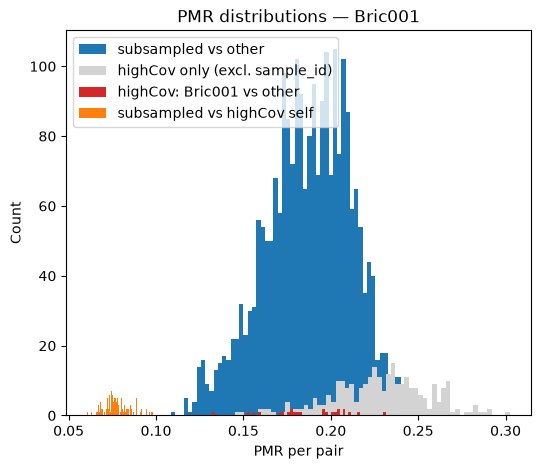

In [75]:
# Build merged pmr table
ph_full_reps = build_replicate_ph_full(replicate_ph_data, n_snps)  # [n_reps, n_snps]

gts = np.vstack([ph.T, ph_full_reps])  # [n_iids + n_reps, n_snps]
iids_merged = list(samples) + [f"{sample_id}_rep{i}" for i in range(n_reps)]

df_pmr_merged = pw_mm_rates_iids(gts=gts, iids=iids_merged, val_missing=-1)

# classify pairs
def is_rep(x):
    return "_rep" in x

df_pmr_merged["id1_is_rep"] = df_pmr_merged["iid1"].apply(is_rep)
df_pmr_merged["id2_is_rep"] = df_pmr_merged["iid2"].apply(is_rep)

# drop rep-vs-rep comparisons (subsampling the same individual against itself, twice)
## note that these give very low pmr (zero) values or NA because they have no overlapping snps usually
df_pmr_merged = df_pmr_merged[~(df_pmr_merged["id1_is_rep"] & df_pmr_merged["id2_is_rep"])].copy()

df_pmr_merged.to_csv("/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/pmr_merged_{sample_id}_python.csv", index=False)

def classify(row):
    is_rep_pair = row["id1_is_rep"] or row["id2_is_rep"]
    involves_self = (row["iid1"] == sample_id) or (row["iid2"] == sample_id)
    if is_rep_pair and involves_self:
        return "subsampled vs highCov self"
    elif is_rep_pair:
        return "subsampled vs other"
    elif involves_self:
        return f"highCov: {sample_id} vs other"
    else:
        return "highCov only (excl. sample_id)"

df_pmr_merged["comparison_type"] = df_pmr_merged.apply(classify, axis=1)
df_pmr_merged = df_pmr_merged.drop(columns=["id1_is_rep", "id2_is_rep"])

print(df_pmr_merged["comparison_type"].value_counts())

# histogram, colored by comparison type
plt.figure(figsize=(6, 5))
ax = plt.gca()

# order matters here: drawn in this sequence, so later entries plot on top
category_colors = {
    "subsampled vs other":             "tab:blue",
    "highCov only (excl. sample_id)": "lightgrey",
    f"highCov: {sample_id} vs other":  "tab:red",
    "subsampled vs highCov self":      "tab:orange",
}

for label, color in category_colors.items():
    if label in df_pmr_merged["comparison_type"].values:
        group = df_pmr_merged[df_pmr_merged["comparison_type"] == label]
        ax.hist(group["pmr"], bins=60, alpha=1, label=label, color=color)

ax.set_xlabel("PMR per pair")
ax.set_ylabel("Count")
ax.set_title(f"PMR distributions — {sample_id}")
ax.legend()
plt.show()

In [76]:
np.sum(ph_full_reps != -1, axis=1)  # [n_reps]

array([1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500,
       1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500, 1500])

In [79]:
## check that I get the same results with the eigenstrat files as here directly. 

def read_eigenstrat_geno(geno_path, ind_path):
    with open(ind_path) as f:
        iids = [line.split()[0] for line in f]
    with open(geno_path) as f:
        rows = [list(line.strip()) for line in f]
    geno = np.array(rows, dtype=int).T  # [n_iids, n_snps]
    return iids, geno

iids_exported, geno_exported = read_eigenstrat_geno(
    f"/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_{sample_id}_subsampled_merged.geno",
    f"/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_{sample_id}_subsampled_merged.ind",
)

rep_check = f"{sample_id}_rep19"
compare_to = "Bric034"  # change to any other high-cov individual to sanity-check against

i1 = iids_exported.index(rep_check)
i2 = iids_exported.index(compare_to)
g1, g2 = geno_exported[i1], geno_exported[i2]

idx_both = (g1 != 9) & (g2 != 9)
mms = np.sum((g1 != g2) & idx_both)
snps = np.sum(idx_both)

print(f"from exported file: mms={mms}, snps={snps}, pmr={mms/snps:.4f}")

row = df_pmr_merged[
    ((df_pmr_merged["iid1"] == rep_check) & (df_pmr_merged["iid2"] == compare_to)) |
    ((df_pmr_merged["iid1"] == compare_to) & (df_pmr_merged["iid2"] == rep_check))
]
print(row)

from exported file: mms=315, snps=1500, pmr=0.2100
         iid1           iid2   pmr  mms  snps      comparison_type
1891  Bric034  Bric001_rep19  0.21  315  1500  subsampled vs other


# Run for all samples

Note that this reuses functions from above. 

In [97]:
n_reps = 100
n_sites = 1500  # change this later, base it on how many overlapping snps I have in the low cov data
n_snps = ad.shape[0]

output_dir = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/run_sims/"

def is_rep(x):
    return "_rep" in x

def classify(row, sample_id):
    is_rep_pair = row["id1_is_rep"] or row["id2_is_rep"]
    involves_self = (row["iid1"] == sample_id) or (row["iid2"] == sample_id)
    if is_rep_pair and involves_self:
        return "subsampled vs highCov self"
    elif is_rep_pair:
        return "subsampled vs highCov"
    else:
        return "highCov only"   # includes sample_id's own highCov-vs-highCov comparisons

In [98]:
def run_sample_pmr(sample_id, ad, ph, samples, n_snps, n_reps=100, n_sites=1500,
                    out_prefix=out_prefix, output_dir=output_dir, save_plot=True):
    """Run the full replicate-subsampling + merged PMR workflow for one
    high-coverage sample_id. Saves an individual histogram + CSV.
    Returns df_pmr_merged for that sample, with a 'sample_id' column added
    so results from multiple samples can later be concatenated."""

    matches = np.where(samples == sample_id)[0]
    if len(matches) == 0:
        raise ValueError(f"Sample ID '{sample_id}' not found in samples array")
    sample_idx = matches[0]

    # build replicates
    replicate_cols = []
    replicate_ph_data = []
    for i in range(n_reps):
        rng = np.random.default_rng(i)
        col, ph_sub, site_idx = build_replicate_column(
            ad, sample_idx, n_snps, n_sites=n_sites, rng=rng, seed=i, verbose=False
        )
        replicate_cols.append(col)
        replicate_ph_data.append((site_idx, ph_sub))

    replicate_geno = np.column_stack(replicate_cols)

    # write eigenstrat files (subsampled-only + merged), same as original
    replicate_ind_lines = [
        f"{sample_id}_rep{i}\tU\t{sample_id}_subsample\n"
        for i in range(n_reps)
    ]
    write_eigenstrat(f"{out_prefix}_{sample_id}_subsampled_only", replicate_geno, replicate_ind_lines)

    merged_geno = np.column_stack([geno_recode, replicate_geno])
    original_ind_lines = [f"{s}\tU\t{pop_label}\n" for s in samples]
    merged_ind_lines = original_ind_lines + replicate_ind_lines
    write_eigenstrat(f"{out_prefix}_{sample_id}_subsampled_merged", merged_geno, merged_ind_lines)

    # build merged pmr table
    ph_full_reps = build_replicate_ph_full(replicate_ph_data, n_snps)
    gts = np.vstack([ph.T, ph_full_reps])
    iids_merged = list(samples) + [f"{sample_id}_rep{i}" for i in range(n_reps)]

    df_pmr_merged = pw_mm_rates_iids(gts=gts, iids=iids_merged, val_missing=-1)

    # classify pairs
    df_pmr_merged["id1_is_rep"] = df_pmr_merged["iid1"].apply(is_rep)
    df_pmr_merged["id2_is_rep"] = df_pmr_merged["iid2"].apply(is_rep)
    df_pmr_merged = df_pmr_merged[
        ~(df_pmr_merged["id1_is_rep"] & df_pmr_merged["id2_is_rep"])
    ].copy()
    df_pmr_merged["comparison_type"] = df_pmr_merged.apply(
        lambda row: classify(row, sample_id), axis=1
    )
    # NEW: flag rows involving sample_id, independent of comparison_type,
    # so we can overlay sample_id's highCov comparisons as a 4th bar
    df_pmr_merged["involves_sample_id"] = (
        (df_pmr_merged["iid1"] == sample_id) | (df_pmr_merged["iid2"] == sample_id)
    )
    df_pmr_merged = df_pmr_merged.drop(columns=["id1_is_rep", "id2_is_rep"])
    df_pmr_merged["sample_id"] = sample_id

    # save csv after filtering/classification, so it matches what's analyzed
    df_pmr_merged.to_csv(f"{output_dir}/pmr_merged_{sample_id}_python.csv", index=False)

    # save plot
    if save_plot:
        sample_colors = {
            "subsampled vs highCov":            "tab:blue",
            "highCov only":                   "lightgrey",
            "subsampled vs highCov self":     "tab:orange",
        }
        plt.figure(figsize=(6, 5))
        ax = plt.gca()

        # background layer: all 3 standard categories, sample_id included in "highCov only"
        for label, color in sample_colors.items():
            if label in df_pmr_merged["comparison_type"].values:
                group = df_pmr_merged[df_pmr_merged["comparison_type"] == label]
                ax.hist(group["pmr"], bins=60, alpha=1, label=label, color=color)

        # fourth bar (solid, on top): sample_id's own highCov-vs-highCov comparisons,
        # double-counted from the grey "highCov only" bars above, drawn deliberately
        self_highcov = df_pmr_merged[
            df_pmr_merged["involves_sample_id"] & (df_pmr_merged["comparison_type"] == "highCov only")
        ]
        if len(self_highcov) > 0:
            ax.hist(self_highcov["pmr"], bins=60, alpha=1, color="tab:red",
                    label=f"{sample_id} vs other highCov")

        ax.set_xlim(0.048, 0.31)
        ax.set_xlabel("PMR per pair")
        ax.set_ylabel("Count")
        ax.set_title(f"PMR distributions — {sample_id}")
        ax.legend()
        plt.tight_layout()
        plt.savefig(f"{output_dir}/pmr_hist_{sample_id}.png", dpi=150)
        plt.close()

    return df_pmr_merged

In [99]:
# loops over every individual in samples (high-coverage sample list).
# for each indiv, calls run_sample_pmr(...) which makes 100 replicates, writes the eigenstrat files, calcs the merged pairwise PMR table, classifies pairs, and saves that sample's  csv and png to output_dir.
# collects each sample's returned df_pmr_merged (with a sample_id column) into all_results.
# after the loop finishes, concatenates all of them into one df_pmr_all dataframe and saves that combined table as a single CSV.


all_results = []
for s in samples:
    print(f"Running {s}...")
    df_s = run_sample_pmr(s, ad, ph, samples, n_snps, n_reps=n_reps, n_sites=n_sites)
    all_results.append(df_s)

df_pmr_all = pd.concat(all_results, ignore_index=True)
df_pmr_all.to_csv(f"{output_dir}/pmr_merged_ALL_samples_python.csv", index=False)

Running Bric001...
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric001_subsampled_only.geno/.snp/.ind for 100 individuals, 537048 SNPs
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric001_subsampled_merged.geno/.snp/.ind for 125 individuals, 537048 SNPs


<positron-console-cell-99>:11: RuntimeWarning: invalid value encountered in scalar divide


Running Bric002...
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric002_subsampled_only.geno/.snp/.ind for 100 individuals, 537048 SNPs
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric002_subsampled_merged.geno/.snp/.ind for 125 individuals, 537048 SNPs


<positron-console-cell-99>:11: RuntimeWarning: invalid value encountered in scalar divide


Running Bric003...
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric003_subsampled_only.geno/.snp/.ind for 100 individuals, 537048 SNPs
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric003_subsampled_merged.geno/.snp/.ind for 125 individuals, 537048 SNPs


...

<positron-console-cell-99>:11: RuntimeWarning: invalid value encountered in scalar divide


Running Bric044...
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric044_subsampled_only.geno/.snp/.ind for 100 individuals, 537048 SNPs
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric044_subsampled_merged.geno/.snp/.ind for 125 individuals, 537048 SNPs


<positron-console-cell-99>:11: RuntimeWarning: invalid value encountered in scalar divide


Running Bric006...
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric006_subsampled_only.geno/.snp/.ind for 100 individuals, 537048 SNPs
Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_Bric006_subsampled_merged.geno/.snp/.ind for 125 individuals, 537048 SNPs


<positron-console-cell-99>:11: RuntimeWarning: invalid value encountered in scalar divide


In [104]:
lowcov_01_reloaded, lowcov_samples_reloaded = read_eigenstrat_to_ph(
    f"{output_dir}/lowcov_filtered.geno",
    f"{output_dir}/lowcov_filtered.ind"
)

NameError: name 'read_eigenstrat_to_ph' is not defined

## How to assign individuals?

Z-score of an observed pmr relative to a candidate's self-baseline,
    adjusting for the fact that pmr precision depends on n_snps (binomial SE
    scales as 1/sqrt(n)). self_std/self_mean come from the candidate's own
    100 replicates, each built from self_baseline_n_sites sites."""
    # scale the baseline SD to the actual number of overlapping sites observed
    adjusted_std = self_std * np.sqrt(self_baseline_n_sites / observed_n_snps)
    z = (observed_pmr - self_mean) / adjusted_std

z_score = (observed_pmr - candidate_self_mean) / candidate_self_std

Step 1 — Get the null (self) distribution
For each candidate, generate 100 simulated self-replicates using n_snps matched to your low-cov comparison. Take the mean and SD of their pmr values — that defines a normal curve specific to that candidate.

Step 2 — Score the observation
For low-cov individual's actual observed pmr against that candidate, evaluate the normal density at that value. Do this for every candidate.

Step 3 — Compare and normalize
Whichever candidate gives the highest density is the best match. Normalize the density values across all candidates (so they sum to 1) to get a posterior probability per candidate.



To implement:
1. Generate self-replicates at the right n_snps per comparison
Right now the replicate loop uses a fixed n_sites=1500 for everyone. You'd need to run that same replicate-generation step again, but with n_sites set to match each low-cov individual's actual number of overlapping SNPs against each candidate — meaning it potentially needs to run once per (low-cov individual, candidate) pair, not once per candidate. This is the main computational cost. 

2. Extract mean and SD from each set of self-replicates
Straightforward — pull the "subsampled vs highCov self" pmr values out of each run's results (same as you already do), and compute their mean and SD. Need to add mean/sd step still. Including the no-match hypothesis. 

3. Compute  low-cov individual's actual observed pmr against each candidate
This is the piece we haven't built yet at all — turning your low-coverage genotype data into pairwise pmr values against your high-coverage samples. This depends entirely on what format your low-cov data is in, which is still an open question from earlier in this conversation. Note, I don't

4. Evaluate a normal density at the observed value, for each candidate
A single function call per candidate (R's dnorm(), using that candidate's mean/SD from step 2 and the observed pmr from step 3).

5. Normalize across candidates into posterior probabilities
Sum the density values (or log-densities, safer numerically) across all candidates for a given low-cov individual, divide each by that sum.

6. repeat for all individuals.


!!!!! Want to add no match somehow... using the distribution from the relateness to the high cov indivs. 
!!!!! need some minimum number of overlaps. 

each low-cov individual has one of four outcomes: 
1. assigned to a specific candidate (high posterior, clear margin), 
2. unrelated/no match (background hypothesis wins), 
3. ambiguous (multiple candidates close together), 
4. insufficient data (too few overlapping SNPs to trust any of the above).

Remember: 𝐿 (𝐻 | 𝐷) = 𝑃(𝐷|𝐻) so likelikhood of a hyp given data = prob of data give hyp. 


H (hypothesis) = "this low-coverage individual is a pseudo-haploid resample of candidate X."

D (data) = the observed pmr value from comparing the low-coverage individual against candidate X's high-coverage genotype.

P(D | H) = "if H is true (this really is candidate X), how probable is it that I'd observe this particular pmr value?" That's exactly what the normal density calculation gives you: you built the distribution of pmr values you'd expect to see if H were true (from the 100 simulated self-replicates), and then asked how probable your actual observed value is under that distribution. The density at that point is P(D|H) — not a probability in the strict sense (density, not probability mass), but that's the standard, correct way to express a likelihood for continuous data.

L(H|D) = P(D|H) — so the likelihood of the hypothesis "this is candidate X," given the data you observed, is just that same density value. You're not computing anything different from P(D|H); the likelihood is P(D|H), evaluated as a function of H (varying which candidate you plug in) while D (your one observed pmr value) stays fixed. That's the entire concept: same formula, just read left-to-right as "probability of the data" or right-to-left as "likelihood of the hypothesis" — they're numerically identical, only the framing/what's held constant differs.

Why you compute it once per candidate: each candidate gives you a different H (different distribution, since each candidate has its own simulated mean/SD), so P(D|H) — and therefore L(H|D) — comes out to a different number for each candidate, even though D (the observed pmr) never changes. That's precisely why comparing L(H₁|D) vs L(H₂|D) vs ... tells you which hypothesis (which candidate) is best supported by the same fixed piece of data.

The "unrelated" hypothesis from the last question fits the same formula — it's just H = "this individual is not any of my candidates," modeled via the background distribution, giving its own P(D|H) to compare against all the candidate-specific ones.

The normalization step (Bayes) goes one level further than pure likelihood: turning L(H|D) into P(H|D) (posterior) requires multiplying by a prior P(H) and dividing by the total probability of the data across all hypotheses — that's a separate, additional step beyond the likelihood itself, though a very natural one to add once you have likelihoods for every candidate.


### bayes rule

The last step converts a likelihood (P(D|H), a number that tells you how well each hypothesis explains the data, but isn't itself a probability that sums to anything meaningful across hypotheses) into a posterior probability (P(H|D), a number that genuinely represents "how probable is this hypothesis, given what I observed," and which does sum to 1 across all your hypotheses). This is just Bayes' rule.

P(H|D) = P(D|H) × P(H) / P(D)
P(D|H) — the likelihood you already have (the normal density at your observed pmr, for each candidate).
P(H) — the prior: how likely you thought each hypothesis was before seeing this particular piece of data. If you have no reason to favor one candidate over another, you'd use a uniform prior (equal probability for every candidate, plus "unrelated"). If you had outside information (e.g., contextual evidence a low-cov sample likely belongs to a specific person based on excavation location), you could weight the prior accordingly.
P(D) — the overall probability of observing this data, averaged across all hypotheses. This is the normalizing constant — it doesn't favor any particular hypothesis, it just rescales everything so the final numbers behave like proper probabilities.

Why you need P(D) at all: your likelihoods alone (the raw density values) don't sum to 1 across candidates — they're just heights on different curves, with no guarantee their total is any particular number. To turn them into genuine probabilities that sum to 1 (so you can say "70% chance it's Bric001, 20% chance Bric002, 10% unrelated"), you have to divide each one by the sum of all of them. That sum-of-all-hypotheses-weighted-by-priors is P(D) — it's not computed independently, it's just built by adding up the numerator (likelihood × prior) across every hypothesis you're considering.

Concretely, in your case:

P(D) = [likelihood(Bric001) × prior(Bric001)] 
     + [likelihood(Bric002) × prior(Bric002)]
     + ... (every other candidate)
     + [likelihood(unrelated) × prior(unrelated)]

Then for each candidate:

P(is Bric001 | observed pmr) = [likelihood(Bric001) × prior(Bric001)] / P(D)

Why this matters practically: without this step, you can rank candidates by raw likelihood (which one has the highest density) — that alone tells you the best candidate. But you can't say anything about how confident you should be, or express it as "70% vs 20% vs 10%," without doing this normalization. It's the step that turns "candidate X scored highest" into "candidate X is 70% likely to be the true match, and here's how that 70% compares to the other possibilities" — which is exactly the kind of confidence statement you said you wanted a few messages back.


Final to do:
- simulate a fake low-cov individual from a known high-cov sample and confirm the method correctly assigns it back